# Bài 1 (Trang 1) – Phân lớp Iris với Decision Tree, Naïve Bayes, KNN, Neural Network

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Câu a) Đọc bộ dữ liệu Iris từ sklearn

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import keras
from keras.models import Sequential
from keras.layers import Dense, Input

import tensorflow as tf
tf.get_logger().setLevel("ERROR")  # ẩn cảnh báo không có GPU
keras.utils.set_random_seed(42)
pd.set_option("display.width", 120)
iris = load_iris()
print("Đã đọc bộ dữ liệu Iris:", type(iris))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Đã đọc bộ dữ liệu Iris: <class 'sklearn.utils._bunch.Bunch'>


## Câu b) Khảo sát bộ dữ liệu Iris

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print("Tên các thuộc tính:", iris.feature_names)
print("Thuộc tính phân lớp (các lớp):", [str(n) for n in iris.target_names])
print("Kích thước data:", iris.data.shape, "- kích thước target:", iris.target.shape)
print("Số lượng mẫu:", iris.data.shape[0], "- Số lượng thuộc tính:", iris.data.shape[1])
print("\n5 mẫu dữ liệu đầu tiên:")
for i in range(5):
    print(iris.data[i], "->", iris.target[i], f"({iris.target_names[iris.target[i]]})")
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print("\nThống kê mô tả:")
print(df.describe())

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Tên các thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Thuộc tính phân lớp (các lớp): ['setosa', 'versicolor', 'virginica']
Kích thước data: (150, 4) - kích thước target: (150,)
Số lượng mẫu: 150 - Số lượng thuộc tính: 4

5 mẫu dữ liệu đầu tiên:
[5.1 3.5 1.4 0.2] -> 0 (setosa)
[4.9 3.  1.4 0.2] -> 0 (setosa)
[4.7 3.2 1.3 0.2] -> 0 (setosa)
[4.6 3.1 1.5 0.2] -> 0 (setosa)
[5.  3.6 1.4 0.2] -> 0 (setosa)

Thống kê mô tả:
       sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
count         150.000000        150.000000         150.000000        150.000000
mean            5.843333          3.057333           3.758000          1.199333
std             0.828066          0.435866           1.765298          0.762238
min             4.300000          2.000000           1.000000          0.100000
25%             5.100000          2.800000           1.600000          

## Câu c) Chuẩn hóa dữ liệu về đoạn [0,1]
Chia mỗi giá trị cho giá trị lớn nhất của cột tương ứng.

In [3]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X = iris.data
Y = iris.target
X_max = X.max(axis=0)
print("Giá trị lớn nhất mỗi cột:", X_max)
X = X / X_max
print("5 dòng đầu sau chuẩn hóa:\n", np.round(X[:5], 4))
print("Min:", X.min(axis=0), "Max:", X.max(axis=0))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Giá trị lớn nhất mỗi cột: [7.9 4.4 6.9 2.5]
5 dòng đầu sau chuẩn hóa:
 [[0.6456 0.7955 0.2029 0.08  ]
 [0.6203 0.6818 0.2029 0.08  ]
 [0.5949 0.7273 0.1884 0.08  ]
 [0.5823 0.7045 0.2174 0.08  ]
 [0.6329 0.8182 0.2029 0.08  ]]
Min: [0.5443038  0.45454545 0.14492754 0.04      ] Max: [1. 1. 1. 1.]


## Câu d) Chia tập train/test theo tỷ lệ 8:2

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
X_train: (120, 4) y_train: (120,)
X_test: (30, 4) y_test: (30,)


## Câu e) Cây quyết định (Decision Tree)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
===== Decision Tree =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



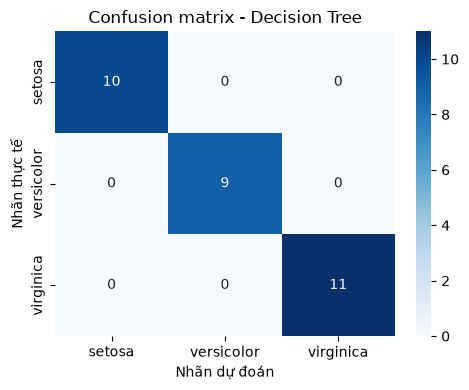

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
def danh_gia(ten_mo_hinh, y_true, y_pred):
    """In Accuracy, classification report va ve confusion matrix bang heatmap."""
    print(f"===== {ten_mo_hinh} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=iris.target_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion matrix - {ten_mo_hinh}")
    plt.tight_layout(); plt.show()

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
danh_gia("Decision Tree", y_test, y_pred_dt)

## Câu f) Naïve Bayes (GaussianNB)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
===== Naive Bayes =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



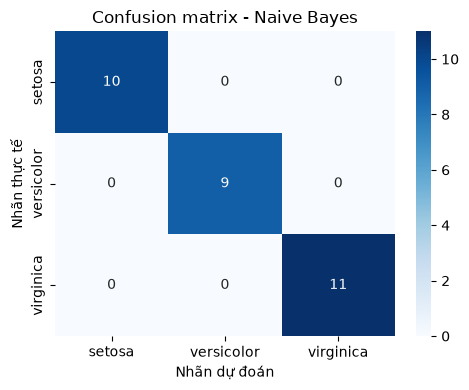

In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
danh_gia("Naive Bayes", y_test, y_pred_nb)

## Câu g) K Nearest Neighbors

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
===== KNN (k=5) =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



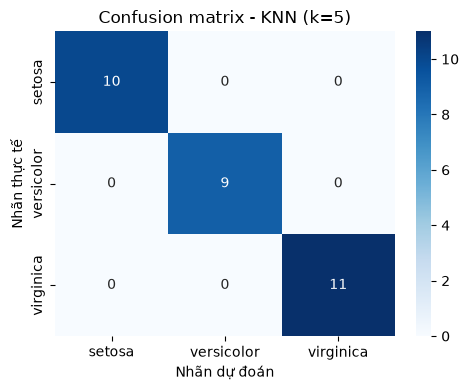

In [7]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
danh_gia("KNN (k=5)", y_test, y_pred_knn)

## Câu h) Neural Network
### Xây dựng và biên dịch mô hình

In [8]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
nn = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(10, activation="relu"),
    Dense(20, activation="relu"),
    Dense(len(iris.target_names), activation="softmax"),
])
nn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
nn.summary()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

### Huấn luyện (epochs=100, batch_size=1, verbose=1)

In [9]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
history = nn.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 905us/step - accuracy: 0.3917 - loss: 1.0245
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 858us/step - accuracy: 0.7750 - loss: 0.8985
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 854us/step - accuracy: 0.9083 - loss: 0.7561
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.8833 - loss: 0.6013
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - accuracy: 0.9000 - loss: 0.4940
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 860us/step - accuracy: 0.9500 - loss: 0.4278
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 910us/step - accuracy: 0.9583 - loss: 0.3835
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step - accuracy: 0.9583 - loss: 0.3494
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 882us/step - accuracy: 0.9583 - loss: 0.3210
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - accuracy: 0.9583 - loss: 0.2966
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/

### Dự đoán và đánh giá

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Xác suất 3 mẫu test đầu:
 [[0.000e+00 9.989e-01 1.100e-03]
 [1.000e+00 0.000e+00 0.000e+00]
 [0.000e+00 1.000e-04 9.999e-01]]
===== Neural Network =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



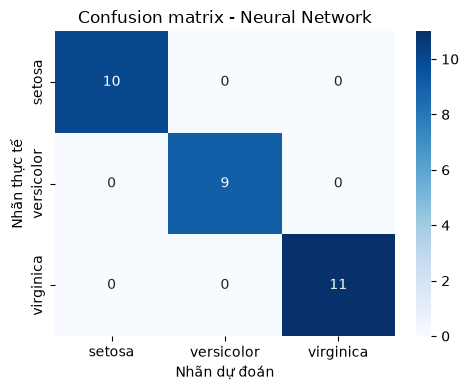

In [10]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
y_prob_nn = nn.predict(X_test, verbose=0)
y_pred_nn = np.argmax(y_prob_nn, axis=1)
print("Xác suất 3 mẫu test đầu:\n", np.round(y_prob_nn[:3], 4))
danh_gia("Neural Network", y_test, y_pred_nn)

## Câu i) Dự đoán 3 mẫu dữ liệu mới
Mẫu mới phải được chuẩn hóa bằng cùng giá trị max của tập dữ liệu gốc.

In [11]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X_new = np.array([[6.2, 2.9, 4.3, 1.3],
                  [5.1, 3.5, 1.4, 0.2],
                  [7.3, 2.8, 6.4, 2.1]])
X_new_norm = X_new / X_max
ket_qua = {
    "Decision Tree": dt.predict(X_new_norm),
    "Naive Bayes": nb.predict(X_new_norm),
    "KNN": knn.predict(X_new_norm),
    "Neural Network": np.argmax(nn.predict(X_new_norm, verbose=0), axis=1),
}
bang = pd.DataFrame({ten: iris.target_names[p] for ten, p in ket_qua.items()},
                    index=[str(x) for x in X_new.tolist()])
print(bang)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
                     Decision Tree Naive Bayes         KNN Neural Network
[6.2, 2.9, 4.3, 1.3]    versicolor  versicolor  versicolor     versicolor
[5.1, 3.5, 1.4, 0.2]        setosa      setosa      setosa         setosa
[7.3, 2.8, 6.4, 2.1]     virginica   virginica   virginica      virginica


## Câu j) Nhận xét, đánh giá hiệu suất các mô hình

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
       Mô hình  Accuracy  Precision  Recall  F1
 Decision Tree       1.0        1.0     1.0 1.0
   Naive Bayes       1.0        1.0     1.0 1.0
           KNN       1.0        1.0     1.0 1.0
Neural Network       1.0        1.0     1.0 1.0


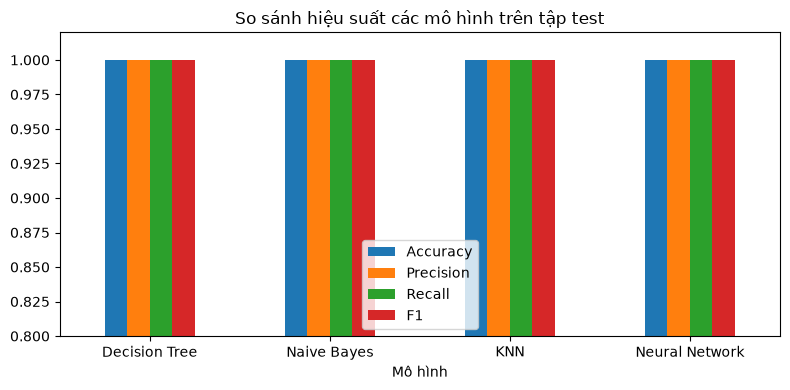


Accuracy 10-fold cross validation trên toàn bộ 150 mẫu:
  Decision Tree : mean = 0.9333, std = 0.0516
  Naive Bayes   : mean = 0.9533, std = 0.0521
  KNN           : mean = 0.9600, std = 0.0533


In [12]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
from sklearn.metrics import precision_recall_fscore_support
rows = []
for ten, yp in [("Decision Tree", y_pred_dt), ("Naive Bayes", y_pred_nb),
                ("KNN", y_pred_knn), ("Neural Network", y_pred_nn)]:
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, average="macro", zero_division=0)
    rows.append([ten, accuracy_score(y_test, yp), p, r, f])
so_sanh = pd.DataFrame(rows, columns=["Mô hình", "Accuracy", "Precision", "Recall", "F1"]).round(4)
print(so_sanh.to_string(index=False))
so_sanh.set_index("Mô hình").plot(kind="bar", figsize=(8, 4), ylim=(0.8, 1.02), rot=0)
plt.title("So sánh hiệu suất các mô hình trên tập test"); plt.tight_layout(); plt.show()

# Tập test chỉ có 30 mẫu -> bổ sung 10-fold cross validation để so sánh ổn định hơn
from sklearn.model_selection import cross_val_score, StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
print("\nAccuracy 10-fold cross validation trên toàn bộ 150 mẫu:")
for ten, m in [("Decision Tree", DecisionTreeClassifier(random_state=42)),
               ("Naive Bayes", GaussianNB()), ("KNN", KNeighborsClassifier(n_neighbors=5))]:
    s = cross_val_score(m, X, Y, cv=skf)
    print(f"  {ten:14s}: mean = {s.mean():.4f}, std = {s.std():.4f}")

**Nhận xét:**

- Trên tập test (30 mẫu, `random_state=42`) cả 4 mô hình Decision Tree, Naïve Bayes, KNN và Neural Network đều đạt Accuracy, Precision, Recall, F1 = 1.0. Iris là bộ dữ liệu nhỏ, các lớp gần như tách biệt tuyến tính theo chiều dài/rộng cánh hoa, nên mô hình nào cũng phân lớp đúng toàn bộ.
- Vì tập test quá nhỏ (mỗi mẫu sai làm giảm ~3.3% accuracy), kết quả 100% chưa đủ để kết luận mô hình nào tốt hơn. Kiểm định chéo 10-fold ở trên cho thấy các mô hình đều đạt khoảng 93–97%; lớp setosa luôn được phân lớp đúng, sai sót chủ yếu nằm giữa versicolor và virginica (hai lớp có vùng giá trị chồng lấn).
- Neural Network cần nhiều thời gian huấn luyện nhất (100 epoch, batch_size = 1) nhưng không cho kết quả vượt trội trên dữ liệu nhỏ này; Naïve Bayes và KNN đơn giản, huấn luyện tức thì mà vẫn chính xác. Decision Tree dễ diễn giải nhưng dễ overfit khi dữ liệu lớn hơn.
- Ở câu i, cả 4 mô hình dự đoán giống nhau: [6.2, 2.9, 4.3, 1.3] → versicolor, [5.1, 3.5, 1.4, 0.2] → setosa, [7.3, 2.8, 6.4, 2.1] → virginica.